# Double-Selection Test of the Factor Zoo

Replicates the double-selection LASSO of Feng, Giglio and Xiu (2020), *Taming the Factor Zoo*, on this project's factors. For each factor, the test asks whether it adds pricing information beyond all the others, measured by its **SDF loading**. A loading that is statistically zero means the other factors already price whatever it prices, so the factor is redundant.

For one test factor:

1. **First selection:** a cross-sectional LASSO of the 25 Fama-French portfolios' average returns on their covariances with the other factors keeps the controls that explain the cross-section of returns.
2. **Second selection:** a cross-sectional LASSO of the portfolios' covariances with the test factor on their covariances with the controls keeps controls that would bias the estimate if omitted.
3. **Post-selection estimate:** an OLS of average returns on covariances with the test factor and the union of selected controls. The coefficient on the test factor is its SDF loading, tested with Newey-West standard errors.

Tuning penalties are chosen by 10-fold cross-validation over random subsets of months, averaged over `N_SEEDS` random splits. Build the inputs first with `python scripts/build_crsp_universe.py` and `python scripts/load_data.py`.

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Parallel workers are fresh processes, so they need the project on their path too
os.environ['PYTHONPATH'] = os.pathsep.join(
    filter(None, [str(PROJECT_ROOT), os.environ.get('PYTHONPATH')])
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed

from modules.factors.mappings import FACTOR_MAPPINGS
from modules.redundancy.double_lasso import (
    _load_test_assets,
    double_selection_test,
)
from modules.redundancy.heatmap import _factor_theme, select_factor_returns
from notebooks.utils import (
    calculate_factor_return_data,
    load_aligned_factor_data,
)

c:\Users\wfpin\Desktop\Projects\factor-originality\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load factor returns and test assets

In [2]:
START_YEAR, END_YEAR = 2004, 2024  # CRSP data ends 2024-12-31

aligned_data = load_aligned_factor_data(start_year=START_YEAR, end_year=END_YEAR)
daily_returns = calculate_factor_return_data(data=aligned_data, start_year=START_YEAR)
del aligned_data  # large panel no longer needed
daily_returns.shape

Factor returns: 100%|██████████| 51/51 [01:14<00:00,  1.45s/it, eleven_one_seasonality_nonannual] 


(5284, 52)

The test is run on monthly returns: daily long-short returns are compounded within each calendar month, and only months in which every factor has a return are kept. The test assets are the 25 value-weighted size and book-to-market portfolios, as excess returns, downloaded from WRDS on first use and cached in `data/test_assets/ff25.csv`.

In [3]:
factors = select_factor_returns(daily_returns.set_index('date'))
all_months = np.expm1(np.log1p(factors).resample('ME').sum(min_count=1))
monthly_returns = all_months.dropna(how='any')
test_assets = _load_test_assets()
print(
    f'{monthly_returns.shape[1]} factors; {len(monthly_returns)} months '
    f'({monthly_returns.index.min():%Y-%m} to {monthly_returns.index.max():%Y-%m}); '
    f'{test_assets.shape[1]} test assets'
)

51 factors; 251 months (2004-01 to 2024-12); 25 test assets


## Run the test for every factor

Each factor is tested against all the others. The factors are independent of each other, so they run in parallel. More seeds make the cross-validated penalties, and therefore the selected controls, more stable; the paper uses 200. Each factor takes roughly half a minute at 20 seeds.

In [4]:
N_SEEDS = 20

def run_test(name):
    result = double_selection_test(
        test_factor=name,
        factors=monthly_returns,
        test_assets=test_assets,
        n_seeds=N_SEEDS,
    )
    return name, result

results = dict(Parallel(n_jobs=-1)(delayed(run_test)(name) for name in monthly_returns))
len(results)

51

In [5]:
summary = pd.DataFrame(
    {
        'theme': {name: _factor_theme(FACTOR_MAPPINGS[name]['func']) for name in results},
        'loading': {name: r.loading for name, r in results.items()},
        'scaled_loading': {name: r.scaled_loading for name, r in results.items()},
        'std_error': {name: r.std_error for name, r in results.items()},
        't_stat': {name: r.t_stat for name, r in results.items()},
        'n_first': {name: len(r.first_selection) for name, r in results.items()},
        'n_second': {name: len(r.second_selection) for name, r in results.items()},
    }
)
summary['significant'] = summary['t_stat'].abs() >= 1.96
summary = summary.reindex(summary['t_stat'].abs().sort_values(ascending=False).index)
print(f"{summary['significant'].sum()} of {len(summary)} factors have a significant SDF loading (|t| >= 1.96)")
summary.round({'loading': 2, 'scaled_loading': 4, 'std_error': 2, 't_stat': 2})

14 of 51 factors have a significant SDF loading (|t| >= 1.96)


,theme,loading,scaled_loading,std_error,t_stat,n_first,n_second,significant
net_total_issuance,value,31.44,0.0062,9.12,3.45,2,3,True
quarterly_sales_growth,investment,-34.85,-0.0098,10.75,-3.24,2,2,True
operating_profit_to_lagged_assets,quality,73.84,0.0378,23.78,3.10,2,2,True
operating_profit_to_assets,quality,90.01,0.0414,31.25,2.88,2,3,True
gross_profitability_lagged,quality,95.07,0.0624,33.27,2.86,2,3,True
assets_turnover,quality,45.92,0.0124,16.09,2.85,2,4,True
noa_change,investment,-24.93,-0.0075,8.90,-2.80,1,1,True
gross_profitability,quality,-89.35,-0.0552,31.96,-2.80,2,2,True
common_equity_change,investment,-41.28,-0.0173,14.83,-2.78,2,3,True
quarterly_return_on_assets,quality,-37.16,-0.0267,13.86,-2.68,2,2,True


## Which factors carry independent pricing information

`scaled_loading` is the loading times the factor's variance: the average monthly excess return of a portfolio with unit univariate beta to the factor, controlling for the selected controls. Its t-statistic is the same as the loading's. A factor with a small t-statistic is redundant given the others; a large one is priced independently.

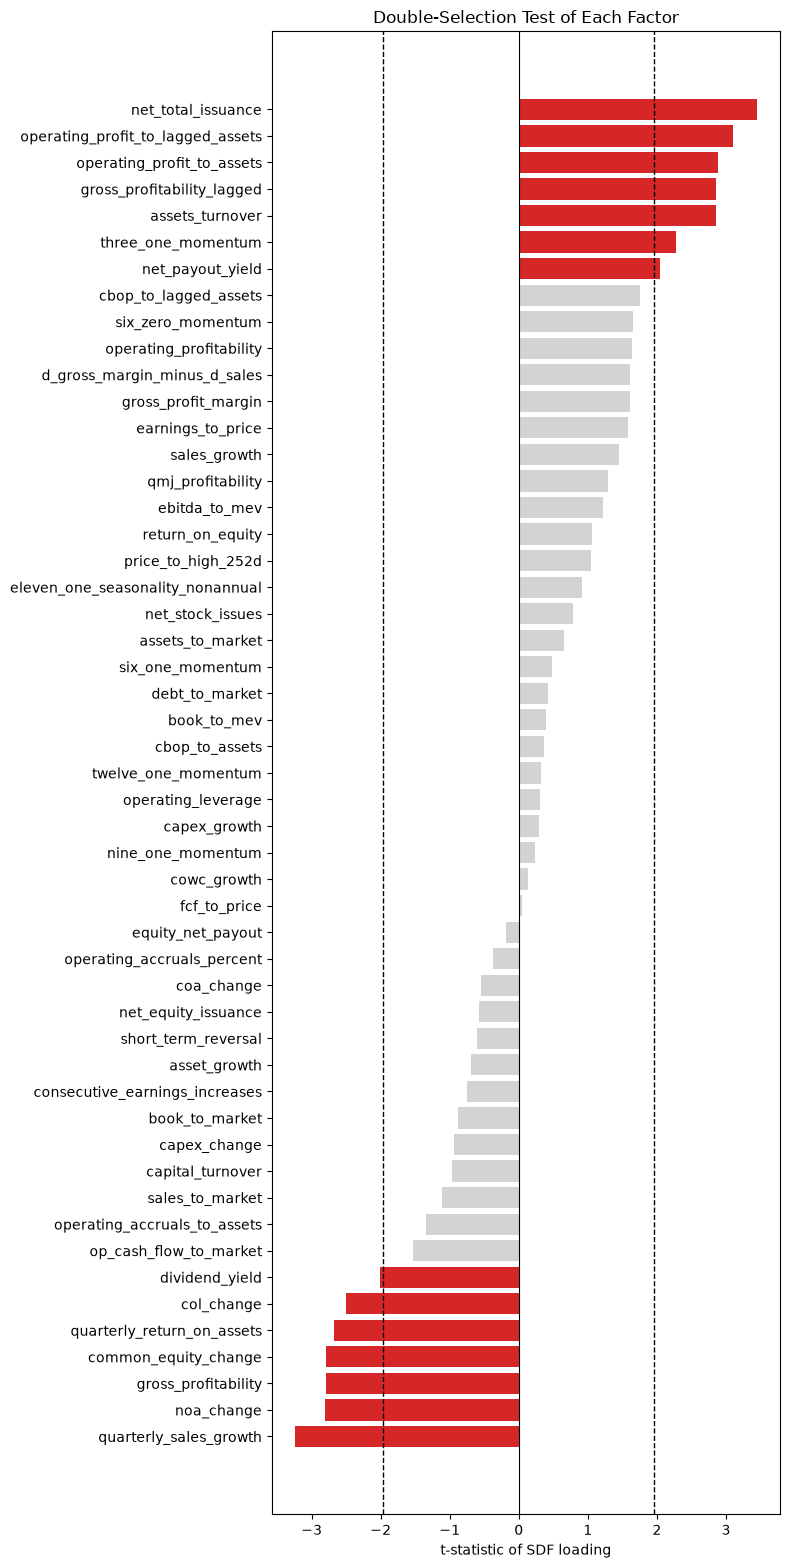

In [6]:
ordered = summary.sort_values('t_stat')
fig, ax = plt.subplots(figsize=(8, 0.28 * len(ordered) + 1.5))
colors = np.where(ordered['significant'], 'tab:red', 'lightgrey')
ax.barh(ordered.index, ordered['t_stat'], color=colors)
for bound in (-1.96, 1.96):
    ax.axvline(bound, color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('t-statistic of SDF loading')
ax.set_title('Double-Selection Test of Each Factor')
plt.tight_layout()
plt.show()

In [7]:
by_theme = summary.groupby('theme').agg(
    factors=('significant', 'size'),
    significant=('significant', 'sum'),
    mean_abs_t=('t_stat', lambda t: t.abs().mean()),
)
by_theme['share_significant'] = by_theme['significant'] / by_theme['factors']
by_theme.sort_values('share_significant', ascending=False).round(2)

,factors,significant,mean_abs_t,share_significant
theme,,,,
investment,9,4,1.69,0.44
quality,16,6,1.78,0.38
value,15,3,1.13,0.20
momentum,8,1,0.94,0.12
accruals,3,0,0.62,0.00


## Which controls were selected

For each tested factor (rows), a cell is marked if the control (column) was kept by the first selection, by the second selection, or by both. Controls kept in many rows are the ones that matter most for pricing, or that overlap most with other factors' exposures.

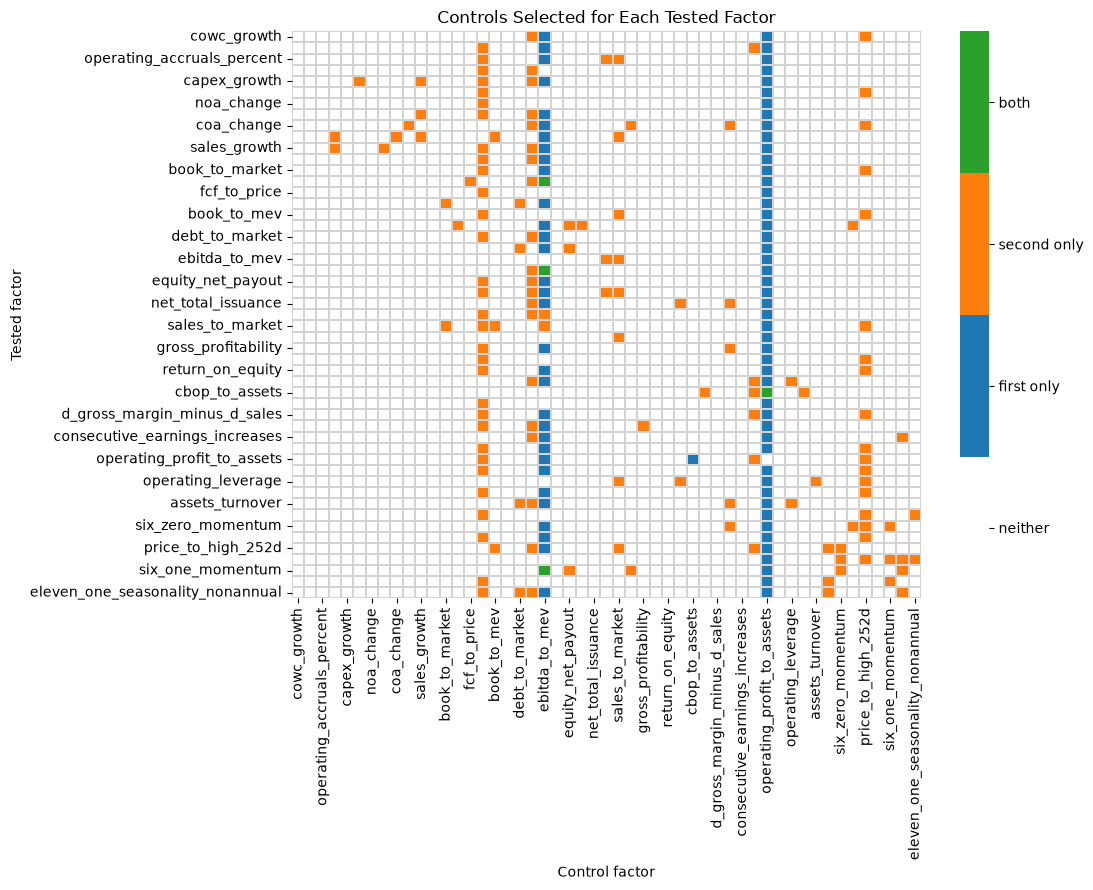

In [8]:
names = list(monthly_returns.columns)
selection = pd.DataFrame(0, index=names, columns=names)
for name, result in results.items():
    for control in result.first_selection:
        selection.loc[name, control] += 1
    for control in result.second_selection:
        selection.loc[name, control] += 2

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    selection,
    ax=ax,
    cmap=sns.color_palette(['white', 'tab:blue', 'tab:orange', 'tab:green']),
    cbar_kws={'ticks': [0.375, 1.125, 1.875, 2.625]},
    linewidths=0.2,
    linecolor='lightgrey',
    vmin=0,
    vmax=3,
)
colorbar = ax.collections[0].colorbar
colorbar.set_ticklabels(['neither', 'first only', 'second only', 'both'])
ax.set_xlabel('Control factor')
ax.set_ylabel('Tested factor')
ax.set_title('Controls Selected for Each Tested Factor')
plt.tight_layout()
plt.show()

In [9]:
frequency = pd.DataFrame(
    {
        'first_selection': selection.isin([1, 3]).sum(),
        'second_selection': selection.isin([2, 3]).sum(),
    }
)
frequency['total'] = frequency.sum(axis=1)
frequency.sort_values('total', ascending=False).head(15)

,first_selection,second_selection,total
operating_profit_to_assets,50,1,51
ebitda_to_mev,35,5,40
assets_to_market,0,31,31
dividend_yield,0,20,20
price_to_high_252d,0,18,18
sales_to_market,0,8,8
quarterly_return_on_assets,0,6,6
gross_profitability_lagged,0,5,5
nine_one_momentum,0,4,4
debt_to_market,0,4,4


## Caveats

- **Few test assets.** The paper prices 200+ portfolios; here there are only 25. The second-stage cross-sectional regression needs fewer selected controls than test assets, so some factors may be hard to estimate precisely.
- **Tuning sensitivity.** Selected controls depend on the cross-validated penalties, which vary with the random splits. Raise `N_SEEDS` (the paper uses 200) before drawing conclusions about individual factors.
- **Sample.** About 250 months of S&P 500 members, a much shorter and more concentrated sample than the paper's.